# Plasticity plotting

This notebook generates plots to visualize neural plasticity post-patching by comparing outputs of a model finetuned using baseline data for baseline and post-patching data. The inference data is expected to exist under settings.INFERENCE_DIR, organized by model name and fold. The notebook allows you to specify which subjects and conditions to visualize.

In [13]:
import os

import numpy as np
from core import plotting
from core import io
from core import settings
import matplotlib.pyplot as plt
from scipy.stats import sem
import mne
from core import plot_data_processing as data_processor
from core.plot_data_processing import rename_chans_to_mne

In [14]:
if os.path.basename(os.getcwd()) == 'notebooks':
    os.chdir('..')

model_name = "llrd_norm_5e-3"
subjects = None # set to None to load all subjects
conditions = ["global"]  # set to None to load all conditions
trial_ids = None #[]  # set to None to load all trial ids
bands = None #[] # set to None to visualize all frequency bands


In [15]:
# select appropriate frequency bands based on user input
if bands is None:
    bands = list(settings.FREQ_BANDS.keys())
else:
    loaded = []
    for band in bands:
        for key in settings.FREQ_BANDS.keys():
            if band in key:
                loaded.append(key)
    bands = loaded

### Filter the inference data to only include the specified subjects, conditions, and trial ids

In [16]:

baseline_folds = []
baseline_merged = []
postpatch_folds = []
postpatch_merged = []

for i in range(1, 7):
    b_file_path = settings.INFERENCE_DIR / model_name / str(i) / "baseline_reconstruction.h5"
    p_file_path = settings.INFERENCE_DIR / model_name / str(i) / "postpatch_reconstruction.h5"


    b_fold_trials = io.load_inference_trials(b_file_path, subjects=subjects, conditions=conditions, idxs=trial_ids)
    baseline_folds.append(b_fold_trials)
    baseline_merged.extend(b_fold_trials)
    p_fold_trials = io.load_inference_trials(p_file_path, subjects=subjects, conditions=conditions, idxs=trial_ids)
    postpatch_folds.append(p_fold_trials)
    postpatch_merged.extend(p_fold_trials)


print(len(baseline_folds))
print(baseline_folds[0][0].metrics.r2_bandwise)

Loading inference trials...
Filtering for subjects: all
Filtering for conditions: global
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: global
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: global
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: global
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: global
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: global
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: global
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: global
Filtering for idxs: all
Loading inference trials...
Filtering for subjects: all
Filtering for conditions: global
Filteri

In [17]:
def get_meta_from_key(key, metadata_fields):
    parts = key.split("/")
    metadata = {}
    for field in metadata_fields:
        if field == "subject":
            for part in parts:
                if part.startswith("STMD"):
                    metadata[field] = part
                    break
        elif field == "idx":
            for part in parts:
                if part.isdigit():
                    metadata[field] = part
    return metadata


def extract_data(all_folds, searched, return_metadata = None, return_keys = False):
    matched = []
    metadata = []
    if return_keys:
        matched = {}
    for fold_data in all_folds:
        for key, data in fold_data.items():
            parts = key.split("/")
            if searched in parts:
                if return_keys:
                    matched[key] = data
                else:
                    matched.append(data)
                if not return_metadata:
                    continue
                metadata.append(get_meta_from_key(key, return_metadata))
    return matched, metadata


def extract_normalized_data(all_folds, normalize_by, searched, bands = None):

    normalized = {band: [] for band in bands} if bands else []
    for fold_data in all_folds:
        for key, data in fold_data.items():
            parts = key.split("/")
            if normalize_by in parts:
                std_axis = data.ndim - 1
                std = np.mean(np.std(data, axis = std_axis, ddof = 1))
                if std == 0:
                    print("Standard deviation is zero for key:", key)
                    continue
                path_parts = [p for p in parts if p != normalize_by]
                matched_key = "/".join(path_parts)

                target_keys = [k for k in fold_data.keys() if f"{matched_key}/" in k and searched in k.split("/")]

                if len(target_keys) == 0:
                    print("Target key not found for key:", key)
                    continue
                if not bands and len(target_keys) > 1:
                    print("WARNING: Multiple target keys found for key:", key, target_keys)
                    continue
                for target_key in target_keys:
                    target_data = fold_data[target_key]
                    if bands:
                        normalized[target_key.split("/")[-1]].append(target_data / std)
                    else:
                        normalized.append(target_data / std)
    return normalized


def avg_over_folds(all_folds, metric):
    matched = []
    for fold_data in all_folds:
        for key, data in fold_data.items():
            parts = key.split("/")
            if metric in parts:
                matched.append(data)
    return np.mean(matched)

def calc_nmae(target, output, channel, sample, bands, freqs): # TODO
    std_axis = target.ndim - 1
    std = np.mean(np.std(target, axis = std_axis, ddof = 1))
    if std == 0:
        print("Standard deviation is zero for channel:", channel, "in sample:", sample)
        metrics = None

    bandwise = {}
    for band_name, band in bands.items():
        low, high = band
        band_indices = np.where((freqs >= low) & (freqs <= high))[0]
        target_band = target[band_indices]
        output_band = output[band_indices]
        band_mae = np.mean(np.abs(target_band - output_band))

        band_std = np.mean(np.std(target_band, axis=std_axis, ddof=1))

        if band_std == 0:
            print("Standard deviation is zero for band:", band_name, "in channel:", channel, "in sample:", sample)
            band_nmae = None
        else:
            band_nmae = band_mae / band_std
        bandwise[band_name] = band_nmae

    metrics = {
        "nmae": np.mean(np.abs(target - output)) / std,
        "bandwise_nmae": bandwise,
    }
    return metrics

def get_channel_maes(channelwise_dataset, n_chans, bands): # TODO
    results = {f"ch_{i}": [] for i in range(n_chans)}

    # Temporary storage to group metrics by trial (subject/condition/idx)
    # structure: grouping[channel][trial_prefix] = {mae, mae_bandwise}
    grouping = {f"ch_{i}": {} for i in range(n_chans)}

    for fold_data in channelwise_dataset:
        for key, value in fold_data.items():
            parts = key.split("/")
            # Expected path: subject/condition/idx/ch_N/metric_name/...
            if len(parts) < 7:
                continue

            trial_prefix = "/".join(parts[1:4]) # e.g., 'STMD_01/global/0'
            channel = parts[5]
            metric_name = parts[6]

            if channel not in grouping:
                continue

            if trial_prefix not in grouping[channel]:
                grouping[channel][trial_prefix] = {
                    band: None for band in bands
                }

            if metric_name == "mae":
                grouping[channel][trial_prefix]["mae"] = value
            elif metric_name == "mae_bandwise" and len(parts) > 7:
                band_name = parts[7]
                if band_name in grouping[channel][trial_prefix]:
                    grouping[channel][trial_prefix][band_name] = value



    # Convert the grouped dictionary into the final list-based structure
    for chan in grouping:
        for trial_prefix, metric_dict in grouping[chan].items():
            target = None
            for fold_data in channelwise_dataset:
                target_key = f"/{trial_prefix}/target"
                if target_key in fold_data:
                    target = fold_data[target_key]
                    break
            if target is None:
                print(f"Target data not found for trial: {trial_prefix}, channel: {chan}")
                continue
            target_std = np.mean(np.std(target[int(chan[3:])], axis=1, ddof=1)) # extract channel index from 'ch_N' format

            freq_window = settings.SPECTRAL_DECODER_PARAMS["freq_window"]
            n_freqs = settings.SPECTRAL_DECODER_PARAMS["n_freqs"]
            freqs = np.geomspace(freq_window[0], freq_window[1], n_freqs)
            bandwise_target_std = {}
            for band_name, band in settings.FREQ_BANDS.items():
                low, high = band
                band_indices = np.where((freqs >= low) & (freqs <= high))[0]
                target_band = target[int(chan[3:]), band_indices]
                bandwise_target_std[band_name] = np.mean(np.std(target_band, axis=1, ddof=1))


            grouping[chan][trial_prefix]["nmae"] = metric_dict["mae"] / (target_std+settings.EPS) if target_std != 0 else 0.0
            for band in settings.FREQ_BANDS.keys():
                band_mae = metric_dict[band]
                band_std = bandwise_target_std[band]
                grouping[chan][trial_prefix][f"nmae_{band}"] = band_mae / (band_std+settings.EPS) if band_std != 0 else 0.0

        results[chan] = list(grouping[chan].values())

    # Example access:

    return results

# Plotting the difference between baseline and post-patching performance

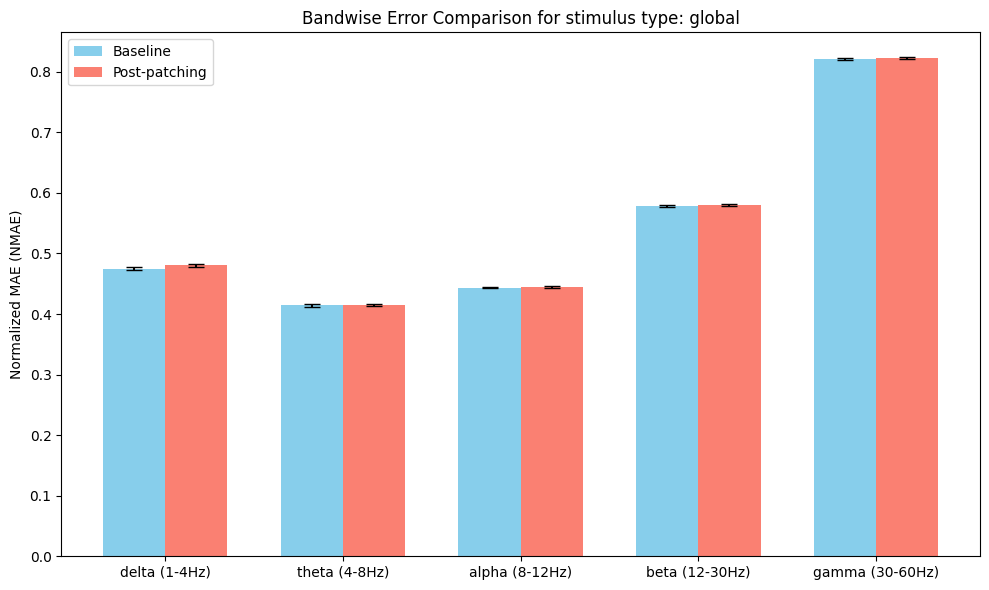

In [18]:


baseline_means, baseline_sems, _ = data_processor.get_bandwise_metric_stats(baseline_merged, metric_name="nmae_bandwise", bands=settings.FREQ_BANDS)
postpatch_means, postpatch_sems, _ = data_processor.get_bandwise_metric_stats(postpatch_merged, metric_name="nmae_bandwise", bands=settings.FREQ_BANDS)

#print(baseline_sems)
# plot bar chart comparing baseline and post-patching nmae for each frequency band with error bars
fig, ax = plt.subplots(figsize=(10, 6))
width = 0.35
x = np.arange(len(settings.FREQ_BANDS))
title = f'Bandwise Error Comparison for stimulus type: {", ".join(conditions)}'

ax.bar(x - width / 2, baseline_means.values(), width=width, yerr=baseline_sems.values(), label='Baseline', color='skyblue', ecolor='black', capsize=6)
ax.bar(x + width / 2, postpatch_means.values(), width=width, yerr=postpatch_sems.values(), label='Post-patching', color='salmon', ecolor='black', capsize=6)
ax.set_xticks(x)
ax.set_xticklabels(baseline_means.keys())

# Formatting
ax.set_ylabel('Normalized MAE (NMAE)')
ax.set_title(f'Bandwise Error Comparison for stimulus type: {", ".join(conditions)}')
ax.legend()
plotting.save_button(fig, save_dir=settings.PLOT_INFERENCE/"bandwise_e_comparison", default_name=f"{model_name}_{'_'.join(conditions)}_error")
plt.tight_layout()
plt.show()

## Single channel comparison viewer

In [19]:
input_metrics = []

input_metrics.append(data_processor.get_channel_viewer_metrics(baseline_merged, ["nmae", "nmae_bandwise"], ))
input_metrics.append(data_processor.get_channel_viewer_metrics(postpatch_merged, ["nmae", "nmae_bandwise"], ))

In [20]:

input_data = [baseline_merged, postpatch_merged]
styling_params = {
        "param_text": "",
        #"suptitle": f"Single channel reconstruction comparison for stimulus type: {', '.join(conditions)}",
        "suptitle": f"Single channel reconstruction comparison for stimulus type: ",
        "apply_log": False,
        "target_mode": "wavelet",
}
save_dir = settings.PLOT_INFERENCE/"single_channel_comparison"/f"{'_'.join(conditions)}"
plotting.single_channel_viewer(input_data, input_metrics, n_chans=settings.N_CHANNELS, styling_params=styling_params, save_dir=save_dir, bands=settings.FREQ_BANDS.keys())

## Topomaps of global and bandwise error for given condition

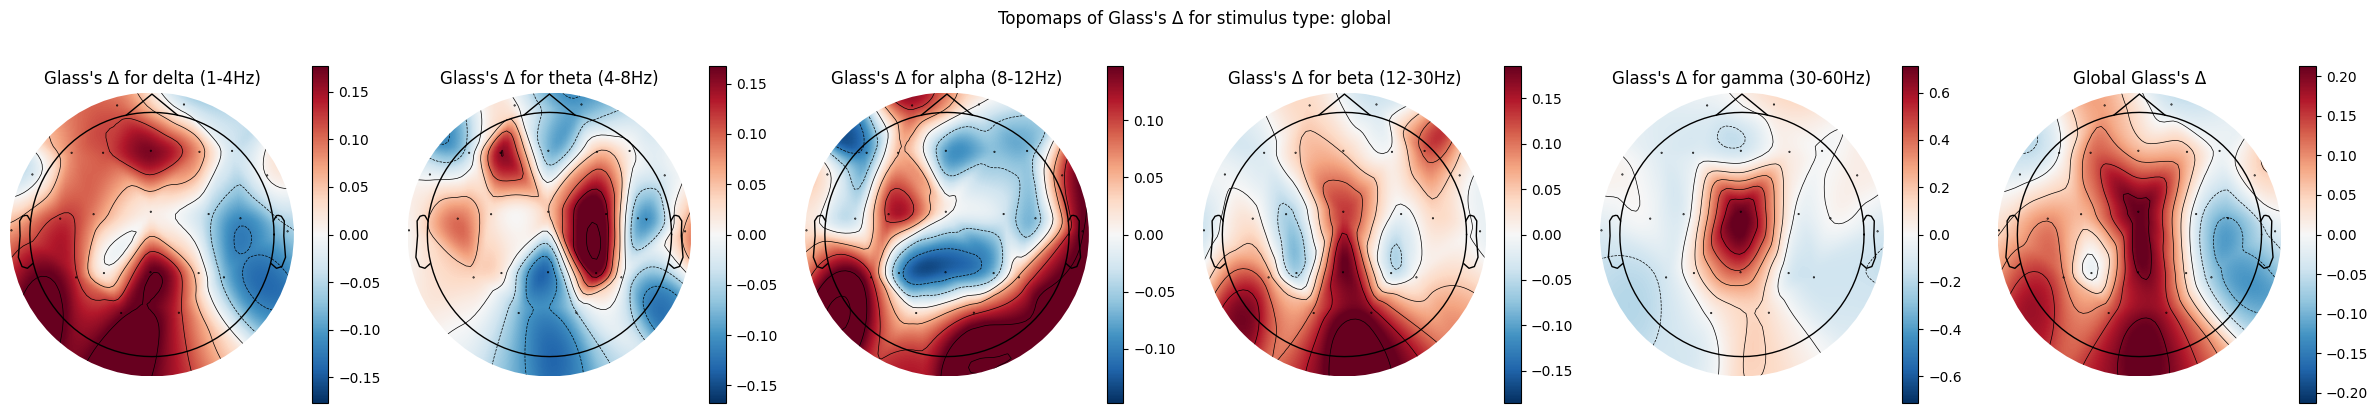

In [21]:


nmae_bw_b, _, std_bw_b = data_processor.get_channel_bandwise_metric_stats(baseline_merged, "nmae_bandwise", bands=settings.FREQ_BANDS)
nmae_bw_p, _, std_bw_p = data_processor.get_channel_bandwise_metric_stats(postpatch_merged, "nmae_bandwise", bands=settings.FREQ_BANDS)
glass_d_ch_bw = data_processor.calc_channel_bandwise_glass_delta(nmae_bw_b, nmae_bw_p, std_bw_b)

nmae_b, _, std_b = data_processor.get_channel_metric_stats(baseline_merged, "nmae")
nmae_p, _, std_p = data_processor.get_channel_metric_stats(postpatch_merged, "nmae")

glass_d_ch_bw["global"] = data_processor.calc_channel_glass_delta(nmae_b, nmae_p, std_b)


ch_names = [settings.CHORDER_STANDARD[i] for i in range(settings.N_CHANNELS)]

rename_chans_to_mne(ch_names)

info = mne.create_info(ch_names=ch_names, sfreq=settings.RSFREQ, ch_types='eeg') # sfreq is required but not relevant for static topomap
montage = mne.channels.make_standard_montage('standard_1005')
info.set_montage(montage)

# create 1x6 subplot for global MAE and each frequency band's MAE with topomap of Glass's delta values
fig, axes = plt.subplots(1, len(glass_d_ch_bw), figsize=(24, 4))

for i, (band, vals) in enumerate(glass_d_ch_bw.items()):

    max_val = max(np.abs(vals))
    vlim = (-max_val, max_val)
    im, _ = mne.viz.plot_topomap(vals, info, axes=axes[i], show=False, vlim=vlim, cmap="RdBu_r")
    if band == "global":
        axes[i].set_title(f"Global Glass's Δ")
    else:
        axes[i].set_title(f"Glass's Δ for {band}")
    fig.colorbar(im, ax=axes[i])
plt.suptitle(f"Topomaps of Glass's Δ for stimulus type: {', '.join(conditions)}", y=1.02)
plotting.save_button(fig, save_dir=settings.PLOT_INFERENCE/"bandwise_topomaps", default_name=f"{model_name}_{'_'.join(conditions)}_topomaps")

plt.tight_layout()
plt.show()


## plotting bandwise amplitude changes pre- and post-patching

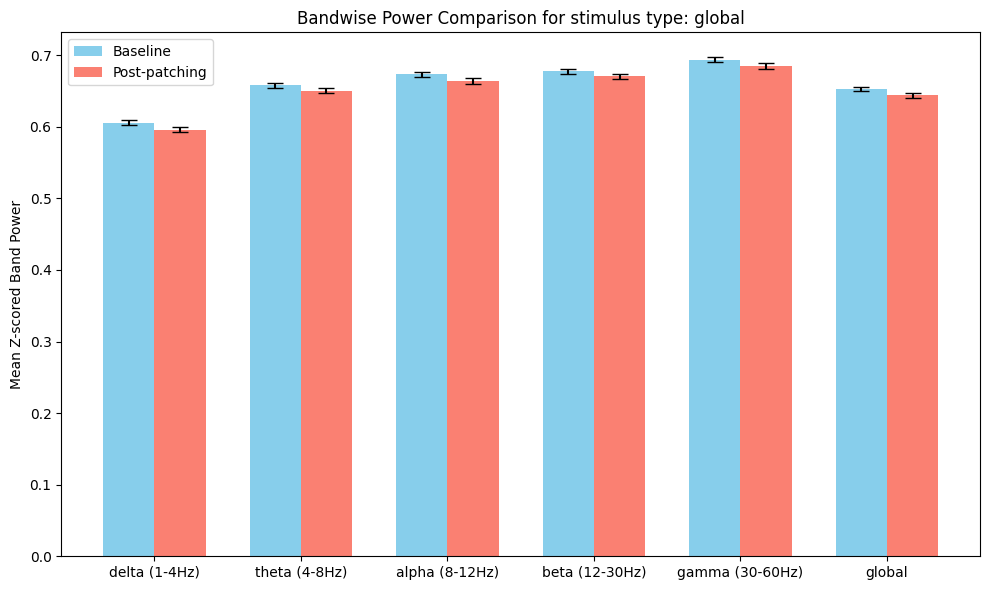

In [22]:
ampl_bw_b, sem_bw_b = data_processor.calc_bandwise_ampl_mean(baseline_merged, bands=settings.FREQ_BANDS, freqs=settings.FREQS)
ampl_bw_p, sem_bw_p = data_processor.calc_bandwise_ampl_mean(postpatch_merged, bands=settings.FREQ_BANDS, freqs=settings.FREQS)

x_text = list(ampl_bw_b.keys())



fig, ax = plt.subplots(figsize=(10, 6))
width = 0.35
x = np.arange(len(x_text))
title = f'Bandwise Power Comparison for stimulus type: {", ".join(conditions)}'

ax.bar(x - width / 2, ampl_bw_b.values(), width=width, yerr=sem_bw_b.values(), label='Baseline', color='skyblue', ecolor='black', capsize=6)
ax.bar(x + width / 2, ampl_bw_p.values(), width=width, yerr=sem_bw_p.values(), label='Post-patching', color='salmon', ecolor='black', capsize=6)
ax.set_xticks(x)
ax.set_xticklabels(x_text)

# Formatting
ax.set_ylabel('Mean Z-scored Band Power')
ax.set_title(title)
ax.legend()

plotting.save_button(fig, save_dir=settings.PLOT_INFERENCE/"bandwise_amplitude", default_name=f"{model_name}_{'_'.join(conditions)}_bw_amps")

plt.tight_layout()
plt.show()

## Subject-wise gamma NMAE comparison pre- and post-patching

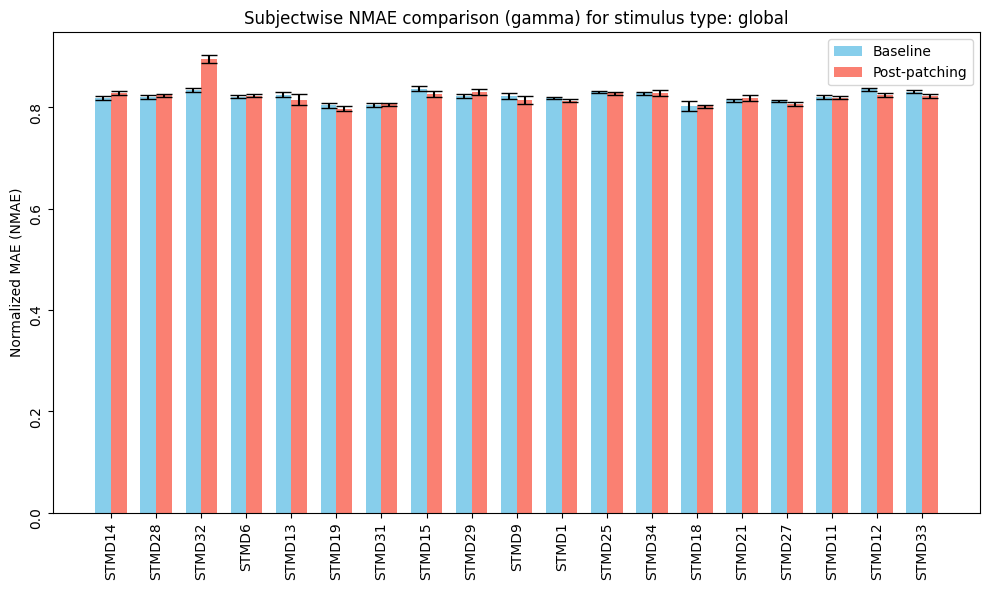

In [23]:
subjectwise_nmae_b, subjectwise_nmae_sem_b = data_processor.calc_subjectwise_metric_stats(baseline_merged, ["gamma (30-60Hz)"], metric="nmae")
subjectwise_nmae_p, subjectwise_nmae_sem_p = data_processor.calc_subjectwise_metric_stats(postpatch_merged, ["gamma (30-60Hz)"], metric="nmae")

band = 'gamma (30-60Hz)'

sb_baseline_nmae = {s: subjectwise_nmae_b[s][band] for s in subjectwise_nmae_b}
sb_baseline_sem  = {s: subjectwise_nmae_sem_b[s][band] for s in subjectwise_nmae_b}
sb_postpatch_nmae = {s: subjectwise_nmae_p[s][band] for s in subjectwise_nmae_b}
sb_postpatch_sem  = {s: subjectwise_nmae_sem_p[s][band] for s in subjectwise_nmae_b}

fig, ax = plt.subplots(figsize=(10, 6))
width = 0.35
x = np.arange(len(subjectwise_nmae_b.keys()))
title = f'Subjectwise NMAE comparison (gamma) for stimulus type: {", ".join(conditions)}'

ax.bar(x - width / 2, sb_baseline_nmae.values(), width=width, yerr=sb_baseline_sem.values(), label='Baseline', color='skyblue', ecolor='black', capsize=6)
ax.bar(x + width / 2, sb_postpatch_nmae.values(), width=width, yerr=sb_postpatch_sem.values(), label='Post-patching', color='salmon', ecolor='black', capsize=6)
ax.set_xticks(x)
ax.tick_params(labelrotation=90)
ax.set_xticklabels(sb_baseline_nmae.keys())

# Formatting
ax.set_ylabel('Normalized MAE (NMAE)')
ax.set_title(title)
ax.legend()
plotting.save_button(fig, save_dir=settings.PLOT_INFERENCE/"bandwise_e_comparison", default_name=f"{model_name}_{'_'.join(conditions)}_nmae_subjectwise_gamma")
plt.tight_layout()
plt.show()


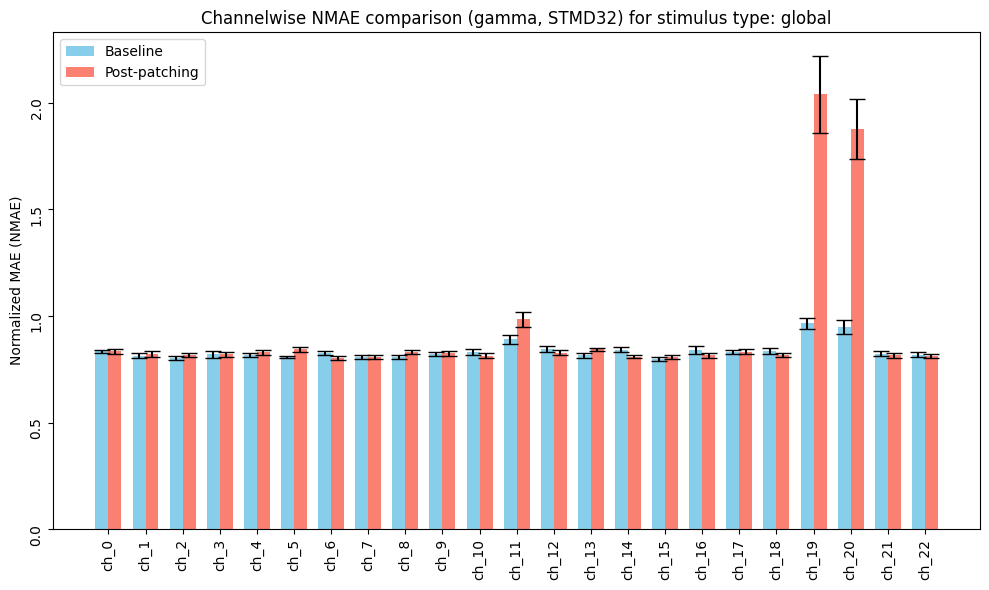

In [24]:
subjectwise_ch_nmae_b, subjectwise_ch_nmae_sem_b = data_processor.calc_subjectwise_channel_metric_stats(baseline_merged, ["gamma (30-60Hz)"], metric="nmae")

subjectwise_ch_nmae_p, subjectwise_ch_nmae_sem_p = data_processor.calc_subjectwise_channel_metric_stats(postpatch_merged, ["gamma (30-60Hz)"], metric="nmae")

sb_baseline_ch_nmae = {ch: band_dict['gamma (30-60Hz)'] for ch, band_dict in subjectwise_ch_nmae_b["STMD32"].items()}
sb_baseline_ch_sem  = {ch: band_dict['gamma (30-60Hz)'] for ch, band_dict in subjectwise_ch_nmae_sem_b["STMD32"].items()}
sb_postpatch_ch_nmae = {ch: band_dict['gamma (30-60Hz)'] for ch, band_dict in subjectwise_ch_nmae_p["STMD32"].items()}
sb_postpatch_ch_sem  = {ch: band_dict['gamma (30-60Hz)'] for ch, band_dict in subjectwise_ch_nmae_sem_p["STMD32"].items()}


fig, ax = plt.subplots(figsize=(10, 6))
width = 0.35
x = np.arange(len(sb_baseline_ch_nmae.keys()))
title = f'Channelwise NMAE comparison (gamma, STMD32) for stimulus type: {", ".join(conditions)}'

ax.bar(x - width / 2, sb_baseline_ch_nmae.values(), width=width, yerr=sb_baseline_ch_sem.values(), label='Baseline', color='skyblue', ecolor='black', capsize=6)
ax.bar(x + width / 2, sb_postpatch_ch_nmae.values(), width=width, yerr=sb_postpatch_ch_sem.values(), label='Post-patching', color='salmon', ecolor='black', capsize=6)
ax.set_xticks(x)
ax.tick_params(labelrotation=90)
ax.set_xticklabels(sb_baseline_ch_nmae.keys())

# Formatting
ax.set_ylabel('Normalized MAE (NMAE)')
ax.set_title(title)
ax.legend()
plotting.save_button(fig, save_dir=settings.PLOT_INFERENCE/"bandwise_e_comparison", default_name=f"{model_name}_{'_'.join(conditions)}_nmae_stmd32_gamma")
plt.tight_layout()
plt.show()